In [2]:
import pandas as pd

path = '../data/raw/tageswerte_KL_05404_19360701_20251231_hist/produkt_klima_tag_19360701_20251231_05404.txt'
df = pd.read_csv(path, sep=';', skipinitialspace=True)
df.shape

(31284, 19)

In [3]:
df.head()

,STATIONS_ID,MESS_DATUM,QN_3,FX,FM,QN_4,RSK,RSKF,SDK,SHK_TAG,NM,VPM,PM,TMK,UPM,TXK,TNK,TGK,eor
0,5404,19360701,-999,-999.0,-999.0,1,4.5,1,10.0,0,4.3,-999.0,-999.0,20.1,-999.0,26.5,12.1,-999.0,eor
1,5404,19360702,-999,-999.0,-999.0,1,3.0,1,0.3,0,7.7,-999.0,-999.0,14.7,-999.0,20.0,12.3,-999.0,eor
2,5404,19360703,-999,-999.0,-999.0,1,0.0,1,10.7,0,4.0,-999.0,-999.0,14.5,-999.0,20.5,10.5,-999.0,eor
3,5404,19360704,-999,-999.0,-999.0,1,3.5,1,6.5,0,4.7,-999.0,-999.0,15.4,-999.0,21.0,9.4,-999.0,eor
4,5404,19360705,-999,-999.0,-999.0,1,0.0,0,10.2,0,3.3,-999.0,-999.0,19.2,-999.0,26.0,9.5,-999.0,eor


In [4]:
import numpy as np

df = df.rename(columns={
    "MESS_DATUM": "date",
    "TMK": "t_mean",
    "TXK": "t_max",
    "TNK": "t_min",
    "TGK": "t_ground_min",
    "RSK": "precip_mm",
    "SDK": "sunshine_h",
    "SHK_TAG": "snow_cm",
    "UPM": "humidity_pct",
})
df = df.drop(columns=["eor"])
df = df.replace(-999, np.nan)
df["date"] = pd.to_datetime(df["date"].astype(str), format="%Y%m%d")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31284 entries, 0 to 31283
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   STATIONS_ID   31284 non-null  int64         
 1   date          31284 non-null  datetime64[us]
 2   QN_3          13602 non-null  float64       
 3   FX            13416 non-null  float64       
 4   FM            13504 non-null  float64       
 5   QN_4          31269 non-null  float64       
 6   precip_mm     31268 non-null  float64       
 7   RSKF          31268 non-null  float64       
 8   sunshine_h    31262 non-null  float64       
 9   snow_cm       25862 non-null  float64       
 10  NM            27883 non-null  float64       
 11  VPM           28707 non-null  float64       
 12  PM            7412 non-null   float64       
 13  t_mean        31269 non-null  float64       
 14  humidity_pct  28675 non-null  float64       
 15  t_max         31269 non-null  float64       
 1

In [5]:
gaps = df['date'].diff()
df.loc[gaps > pd.Timedelta(days=1), 'date']

25021   2008-11-08
Name: date, dtype: datetime64[us]

In [8]:
df.iloc[25018:25023]

,STATIONS_ID,date,QN_3,FX,FM,QN_4,precip_mm,RSKF,sunshine_h,snow_cm,NM,VPM,PM,t_mean,humidity_pct,t_max,t_min,t_ground_min
25018,5404,2004-12-29,NaN,NaN,NaN,3.0,1.2,4.0,0.4,NaN,NaN,NaN,NaN,-0.4,NaN,0.4,-2.3,-4.2
25019,5404,2004-12-30,NaN,NaN,NaN,3.0,0.0,0.0,3.5,NaN,NaN,NaN,NaN,-3.1,NaN,0.1,-7.7,-8.5
25020,5404,2004-12-31,NaN,NaN,NaN,3.0,0.2,4.0,0.0,NaN,NaN,NaN,NaN,-0.5,NaN,2.2,-5.3,-4.9
25021,5404,2008-11-08,10.0,2.0,0.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25022,5404,2008-11-09,10.0,5.1,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Matplotlib is building the font cache; this may take a moment.


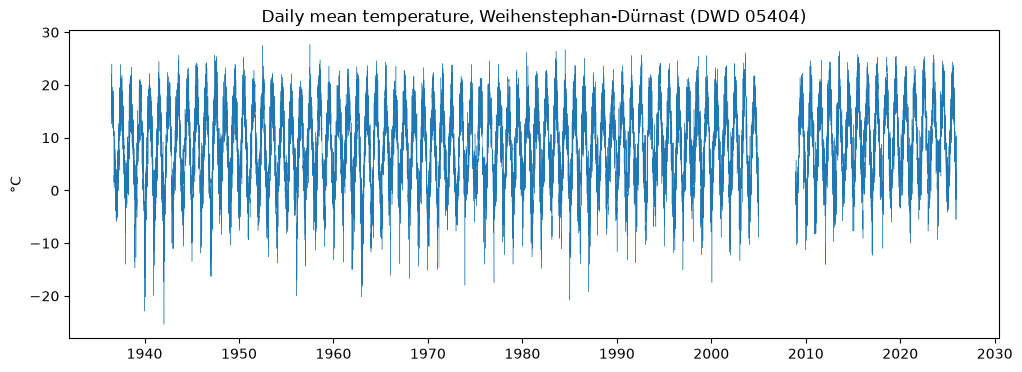

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["date"], df["t_mean"], linewidth=0.3)
ax.set_title("Daily mean temperature, Weihenstephan-Dürnast (DWD 05404)")
ax.set_ylabel("°C")
plt.show()

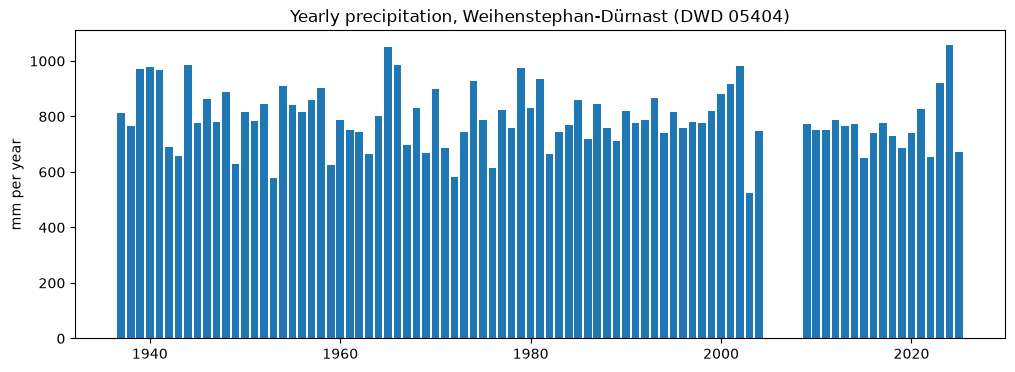

In [7]:
yearly = df.set_index("date")["precip_mm"].resample("YE").sum(min_count=330)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(yearly.index.year, yearly.values)
ax.set_title("Yearly precipitation, Weihenstephan-Dürnast (DWD 05404)")
ax.set_ylabel("mm per year")
plt.show()

## Observations

1. **Temporal Gap in Data:** A complete 1,407-day data hiatus occurs between January 1, 2005, and November 7, 2008. This presents a notable limitation for continuous baseline analysis within the target 1990–2025 window, specifically omitting complete wheat growing seasons across those four years.
2. **Precipitation Distribution & Anomalies:** Annual precipitation typically ranges between 600 mm and 900 mm. A significant dip is observable in 2004 right before the record breaks, which warrants further verification against metadata files to determine whether it reflects a true localized drought or early instrument degradation prior to station relocation.
3. **Thermal Oscillations & Range:** Daily mean temperatures regularly fluctuate between seasonal extremes of approximately -20°C in winter to over +25°C in summer across the 90-year record. While visual inspection indicates baseline seasonal stability, detailed statistical indicators will be required in subsequent steps to quantify long-term climate trends.